# Lab Assignment 2 - HDBSCAN on Iris
## JS08 - Hierarchical Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097

The Iris dataset is clustered without using its species labels. PCA is used only for visualization; HDBSCAN receives all four measurements.

In [1]:
# Install HDBSCAN into the active notebook kernel environment.
%pip install hdbscan

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Number of clusters formed: 2
Noise observations: 2
PCA explained variance: 0.958


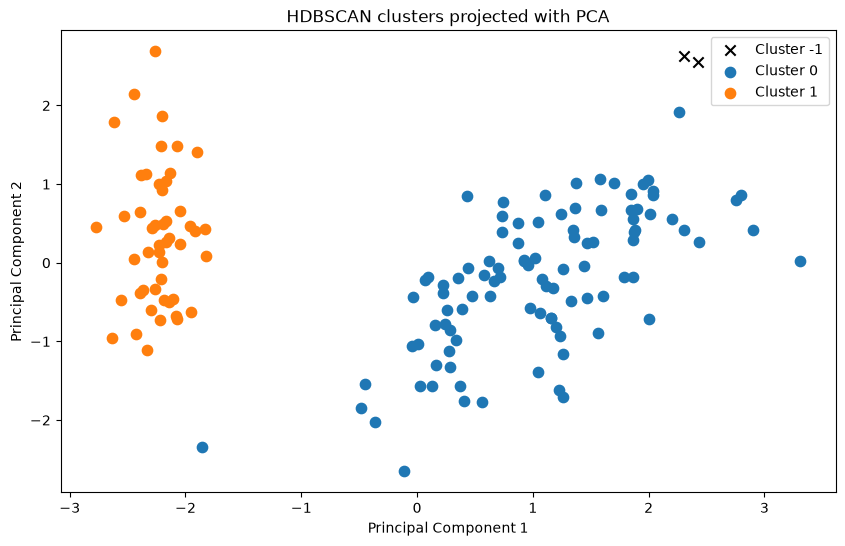

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y_true = iris.target
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)

model = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5).fit(X)
labels = model.labels_
clusters = sorted(set(labels) - {-1})
noise = int((labels == -1).sum())
print(f'Number of clusters formed: {len(clusters)}')
print(f'Noise observations: {noise}')
print(f'PCA explained variance: {pca.explained_variance_ratio_.sum():.3f}')

plt.figure(figsize=(10, 6))
for cluster in sorted(set(labels)):
    mask = labels == cluster
    color = 'black' if cluster == -1 else plt.cm.tab10(cluster % 10)
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], c=[color], s=55,
                marker='x' if cluster == -1 else 'o', label=f'Cluster {cluster}')
plt.title('HDBSCAN clusters projected with PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.show()

In [3]:
mask = labels != -1
if len(np.unique(labels[mask])) >= 2:
    print(f'Silhouette score (non-noise): {silhouette_score(X[mask], labels[mask]):.4f}')
    print(f'Davies-Bouldin Index (non-noise): {davies_bouldin_score(X[mask], labels[mask]):.4f}')
else:
    print('Internal metrics are undefined because fewer than two non-noise clusters were formed.')

print(f'Adjusted Rand Index against original species: {adjusted_rand_score(y_true, labels):.4f}')
comparison = pd.crosstab(pd.Series(y_true, name='Original species'),
                         pd.Series(labels, name='HDBSCAN cluster'))
display(comparison)

Silhouette score (non-noise): 0.5853
Davies-Bouldin Index (non-noise): 0.5833
Adjusted Rand Index against original species: 0.5394


HDBSCAN cluster,-1,0,1
Original species,,,
0,0,1,49
1,0,50,0
2,2,48,0


### Analysis
HDBSCAN is unsupervised, so species labels are not supplied during fitting. The contingency table and Adjusted Rand Index show how closely the discovered groups correspond to the three original species. Agreement is expected to be strongest for setosa; versicolor and virginica overlap in feature space, so they may not be perfectly separated. Noise points are not counted as ordinary clusters.